In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'C:/Users/hibah/rd/Final_SDM_Data.csv')

In [3]:
from sklearn.model_selection import train_test_split

# Automate feature selection by excluding metadata/targets
non_predictors = ['presence', 'koppen_zone', 'decimalLongitude', 'decimalLatitude']
predictor_cols = [col for col in df.columns if col not in non_predictors]

# Assign X and y using the dynamically generated list
X = df[predictor_cols]
y = df['presence']

# Split before scaling/PCA to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data ONLY, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

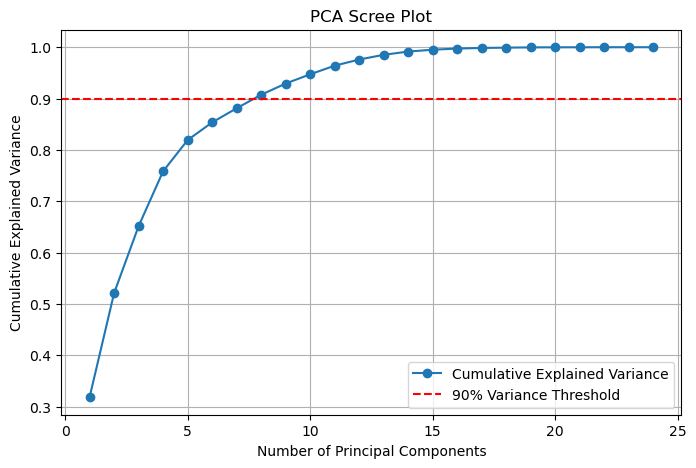

In [5]:
from sklearn.decomposition import PCA
# Fit PCA on training data to determine explained variance
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Plot Scree Plot
plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    np.cumsum(pca_full.explained_variance_ratio_),
    marker='o',
    label='Cumulative Explained Variance'
)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Determine exactly how many components are needed for 90% variance
n_components = np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.90) + 1
print(f"Number of components selected: {n_components}")

# Apply PCA with selected components
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

Number of components selected: 8


In [7]:
#modelling

In [8]:
#split data

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_params = {
    'n_estimators': [100, 200, 500],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

rf_grid.fit(X_train_pca, y_train)

rf_best = rf_grid.best_estimator_

print(rf_grid.best_params_)

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500}


In [10]:
from sklearn.tree import DecisionTreeClassifier

dt_params = {
    'max_depth': [3, 5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

dt_grid.fit(X_train_pca, y_train)

dt_best = dt_grid.best_estimator_
print("Best Parameters:", dt_grid.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}


In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

knn_grid.fit(X_train_pca, y_train)

knn_best = knn_grid.best_estimator_
print("Best Parameters:", knn_grid.best_params_)

Best Parameters: {'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'distance'}


In [12]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV

# Note the 'estimator__' prefix required because SVC is now wrapped inside CalibratedClassifierCV
svm_params = {
    'estimator__C': [0.1, 1, 10, 100],
    'estimator__gamma': ['scale', 0.1, 0.01, 0.001],
    'estimator__kernel': ['rbf', 'linear']
}

# Wrap SVC to calculate probabilities without the deprecated probability=True flag
calibrated_svc = CalibratedClassifierCV(SVC(), ensemble=False)

svm_grid = GridSearchCV(
    calibrated_svc,
    svm_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

svm_grid.fit(X_train_pca, y_train)

svm_best = svm_grid.best_estimator_

print("Best Parameters:", svm_grid.best_params_)

Best Parameters: {'estimator__C': 10, 'estimator__gamma': 0.1, 'estimator__kernel': 'rbf'}


In [13]:
from sklearn.linear_model import LogisticRegression

lr_params = {
    'C': [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=5000),
    lr_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

lr_grid.fit(X_train_pca, y_train)

lr_best = lr_grid.best_estimator_
print("Best Parameters:", lr_grid.best_params_)

Best Parameters: {'C': 10}


In [17]:
from xgboost import XGBClassifier

xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1]
}

xgb_grid = GridSearchCV(
    XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    xgb_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

xgb_grid.fit(X_train_pca, y_train)

xgb_best = xgb_grid.best_estimator_
print("Best Parameters:", xgb_grid.best_params_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:,1]
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = None

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": auc
    }

In [23]:
results = pd.DataFrame({
    "Random Forest": evaluate_model(rf_best, X_test_pca, y_test),
    "Decision Tree": evaluate_model(dt_best, X_test_pca, y_test),
    "KNN": evaluate_model(knn_best, X_test_pca, y_test),
    "Logistic": evaluate_model(lr_best, X_test_pca, y_test),
    "XGBoost": evaluate_model(xgb_best, X_test_pca, y_test),
    "SVM": evaluate_model(svm_best, X_test_pca, y_test)
}).T

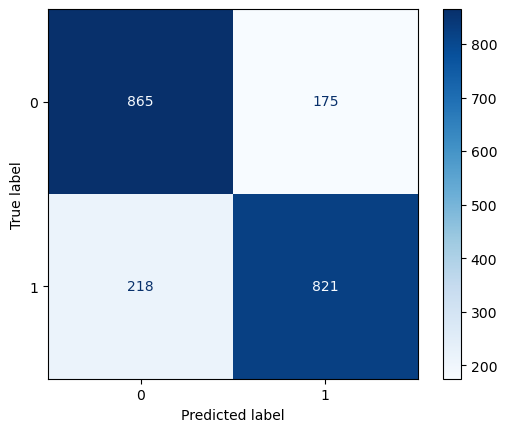

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
y_pred = rf_best.predict(X_test_pca)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.show()

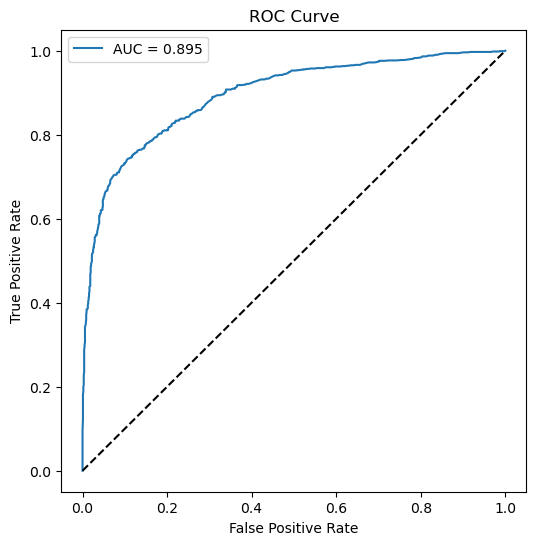

In [21]:
from sklearn.metrics import roc_curve, auc
y_prob = rf_best.predict_proba(X_test_pca)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test,y_prob):.3f}')
plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

plt.show()

In [24]:
results.sort_values(
    by="ROC_AUC",
    ascending=False
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Random Forest,0.810967,0.824297,0.790183,0.806880,0.894877
KNN,0.809043,0.797774,0.827719,0.812470,0.885451
XGBoost,0.801347,0.810516,0.786333,0.798241,0.884811
SVM,0.785955,0.791176,0.776708,0.783876,0.861796
Logistic,0.738336,0.729379,0.757459,0.743154,0.808040
Decision Tree,0.748437,0.775053,0.699711,0.735458,0.803022
